# 07 · Evaluation
Rolling-origin backtest, same universe and K for both approaches.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT))
import os; os.chdir(ROOT)
import pandas as pd, numpy as np
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
from src.utils import load_config
cfg = load_config()
from IPython.display import Image, display

In [2]:
s = pd.read_csv('outputs/metrics/backtest_metrics_summary.csv'); s[s.k==10].round(3)

,method,k,precision_at_k,top_decile_precision_at_k,mean_d_share_pp_at_k,median_d_share_pp_at_k,mean_export_growth_log_at_k,ndcg_at_k,overlap_true_top_k,spearman_all
1,Historical momentum (baseline),10,0.325,0.150,-6.467,-3.214,-1.670,0.112,0.100,-0.115
5,ML alternative family (HGB),10,0.500,0.300,-0.774,0.548,-0.702,0.139,0.050,0.102
9,ML ranking,10,0.550,0.375,-0.928,1.322,-0.658,0.123,0.050,0.102
13,ML without tariff features,10,0.600,0.400,0.141,1.650,-0.555,0.137,0.050,0.096
17,Share-momentum (alt. baseline),10,0.175,0.125,-13.328,-9.661,-0.828,0.078,0.025,-0.117


In [3]:
pd.read_csv('outputs/metrics/backtest_metrics_by_year.csv').query('k==10')[['year','method','precision_at_k','mean_d_share_pp_at_k','ndcg_at_k']].round(3)

,year,method,precision_at_k,mean_d_share_pp_at_k,ndcg_at_k
1,2021,Historical momentum (baseline),0.5,-3.907,0.160
5,2021,ML ranking,0.7,4.196,0.283
9,2021,ML without tariff features,0.7,4.050,0.280
13,2021,ML alternative family (HGB),0.7,5.538,0.365
17,2021,Share-momentum (alt. baseline),0.4,-7.131,0.274
21,2022,Historical momentum (baseline),0.2,-16.286,0.008
25,2022,ML ranking,0.6,-1.293,0.055
29,2022,ML without tariff features,0.6,-1.293,0.054
33,2022,ML alternative family (HGB),0.6,-0.626,0.071
37,2022,Share-momentum (alt. baseline),0.2,-20.112,0.010


In [4]:
pd.read_csv('outputs/metrics/pooled_topk_bootstrap.csv').round(3)

,method,n_picks,mean,ci_low,ci_high,precision
0,Historical momentum (baseline),40,-6.467,-12.284,-1.090,0.325
1,ML ranking,40,-0.928,-3.953,1.708,0.550


In [5]:
pd.read_csv('outputs/rankings/shortlist_comparison_%d.csv' % cfg['years']['test_years'][-1], dtype={'hs6': str})

,iso3,hs6,rank_baseline,rank_ml,in,market,short_desc,category,imp_ind,share_ind,tariff_adv,g3_ind,score_ml,y_d_share_pp,y_export_growth_log
0,AUS,293399,NaN,1.0,ml only,Australia,Heterocyclic compounds; n.e.c. in headings no....,Chemicals & pharmaceuticals,5.642296e+06,7.773341,0.00000,-0.588263,1.893568,-1.324094,-0.292591
1,AUS,730511,2.0,NaN,baseline only,Australia,Iron or steel (excluding cast iron); line pipe...,Base metals & articles,4.684130e+07,7.205650,-5.00000,2.050494,0.828029,14.006132,0.235929
2,AUS,732591,NaN,8.0,ml only,Australia,Iron; grinding balls and similar articles for ...,Base metals & articles,2.909964e+07,21.110011,-5.00000,-0.102147,1.286530,-10.486754,-0.814330
3,CAN,320419,NaN,10.0,ml only,Canada,"Dyes; n.e.c., including mixtures of colouring ...",Chemicals & pharmaceuticals,5.348171e+06,25.408849,0.00000,-0.191422,1.146158,4.316922,0.308520
4,CAN,732591,NaN,6.0,ml only,Canada,Iron; grinding balls and similar articles for ...,Base metals & articles,1.120401e+07,42.295829,0.00000,0.027368,1.367015,-28.917589,-1.209278
5,EUN,290220,NaN,9.0,ml only,European Union,Cyclic hydrocarbons; benzene,Chemicals & pharmaceuticals,5.441653e+07,9.345095,0.00000,-0.607022,1.198950,-9.326800,-5.910833
6,EUN,290243,NaN,3.0,ml only,European Union,Cyclic hydrocarbons; p-xylene,Chemicals & pharmaceuticals,1.312064e+07,7.223346,0.00000,-0.673816,1.615125,-1.058119,-0.416734
7,EUN,520523,NaN,7.0,ml only,European Union,"Cotton yarn; (not sewing thread), single, of c...",Textiles & apparel,4.017286e+07,25.151993,0.00000,-0.176684,1.350250,-5.576864,-0.387192
8,EUN,730511,7.0,NaN,baseline only,European Union,Iron or steel (excluding cast iron); line pipe...,Base metals & articles,1.200440e+07,7.387042,0.00000,1.353860,-0.434695,31.763026,1.533877
9,GBR,294110,8.0,NaN,baseline only,United Kingdom,Antibiotics; penicillins and their derivatives...,Chemicals & pharmaceuticals,1.377581e+07,15.684848,0.00000,1.273303,-3.410176,30.482764,0.867355


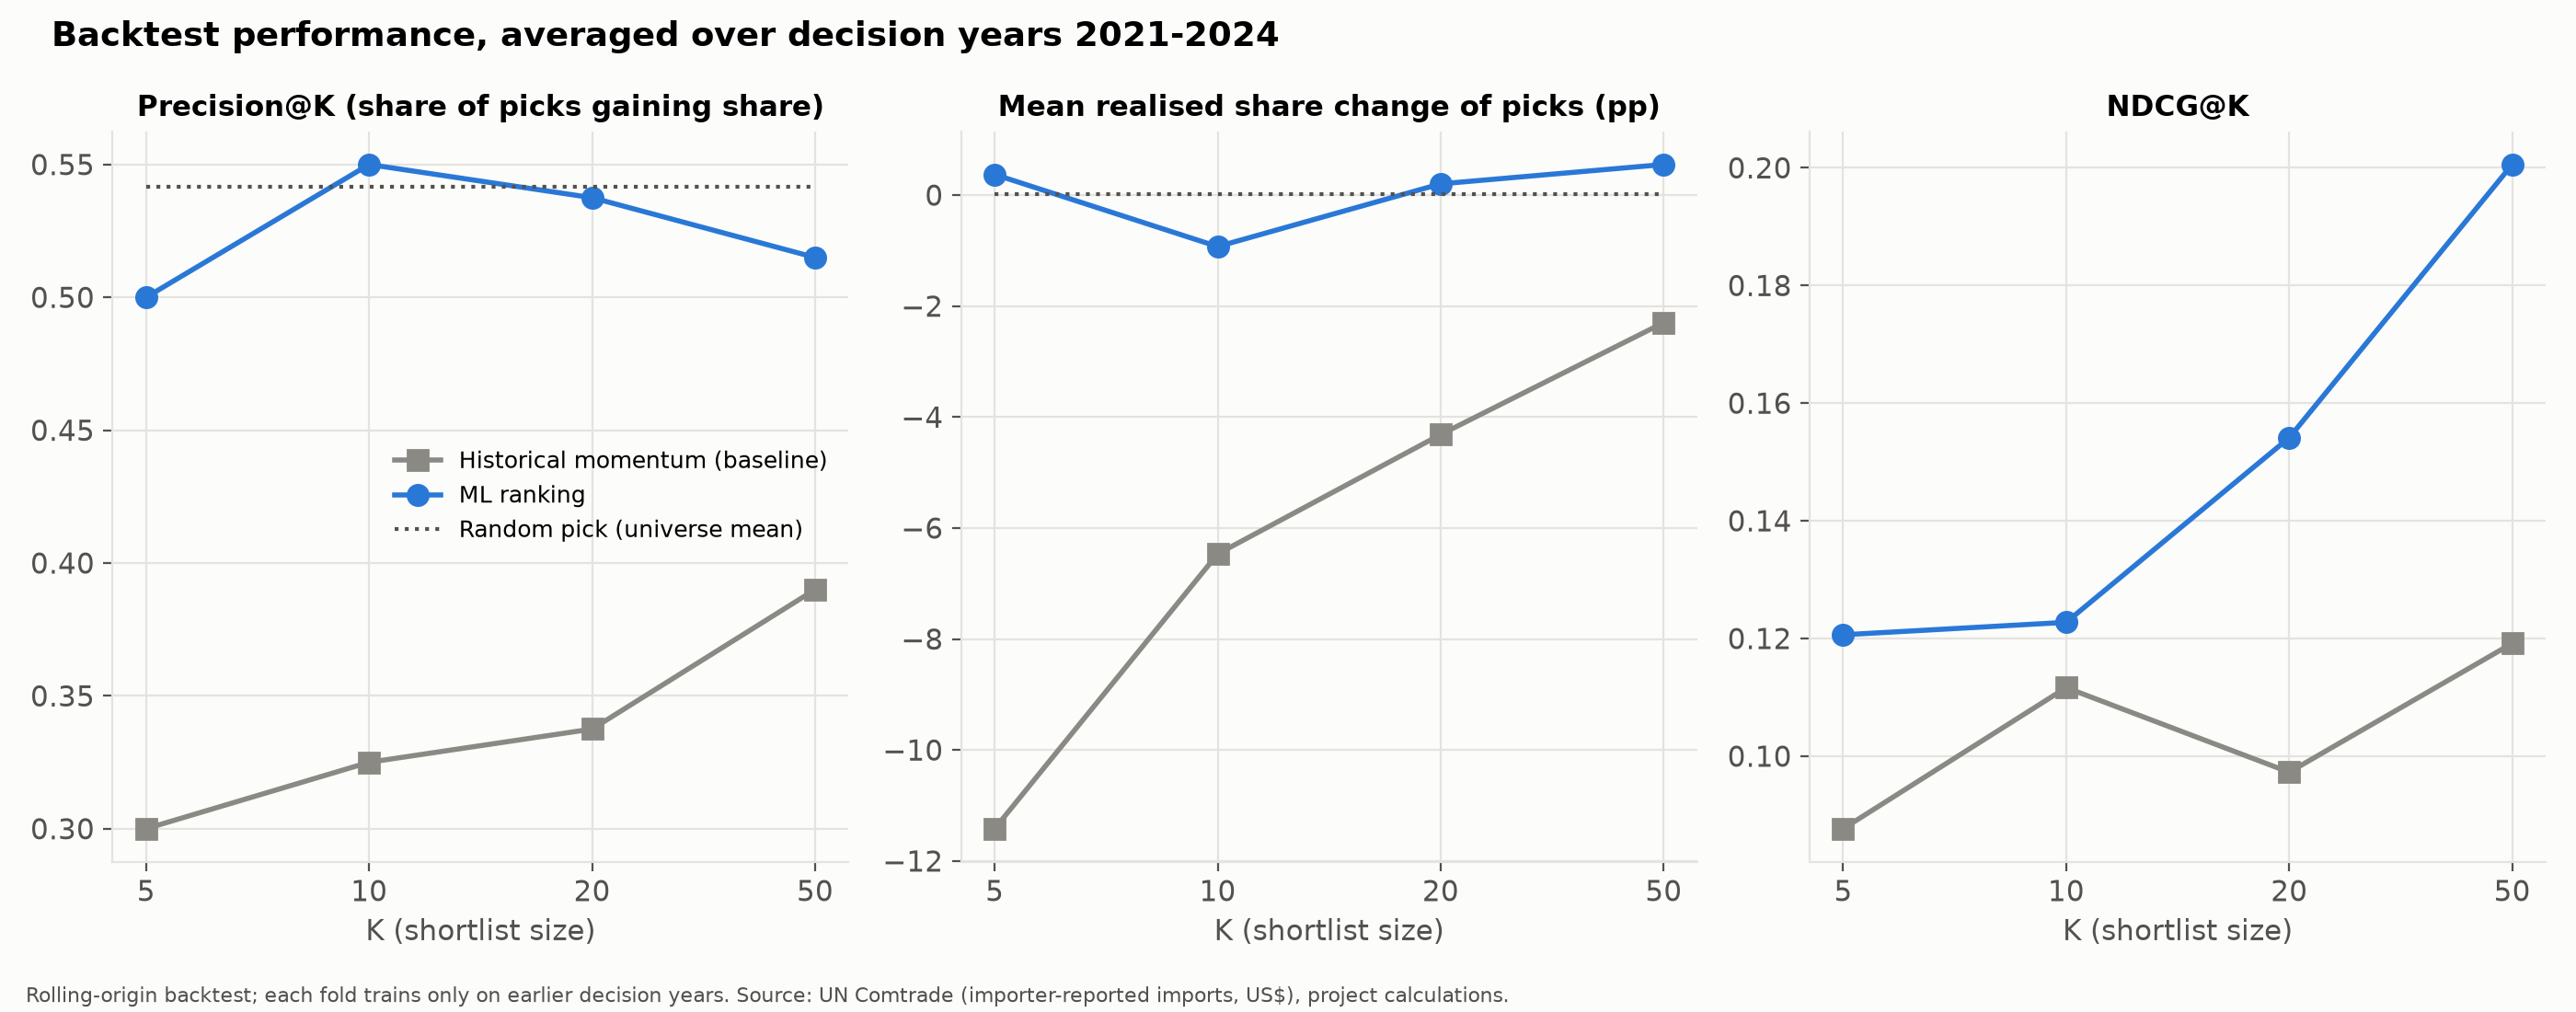

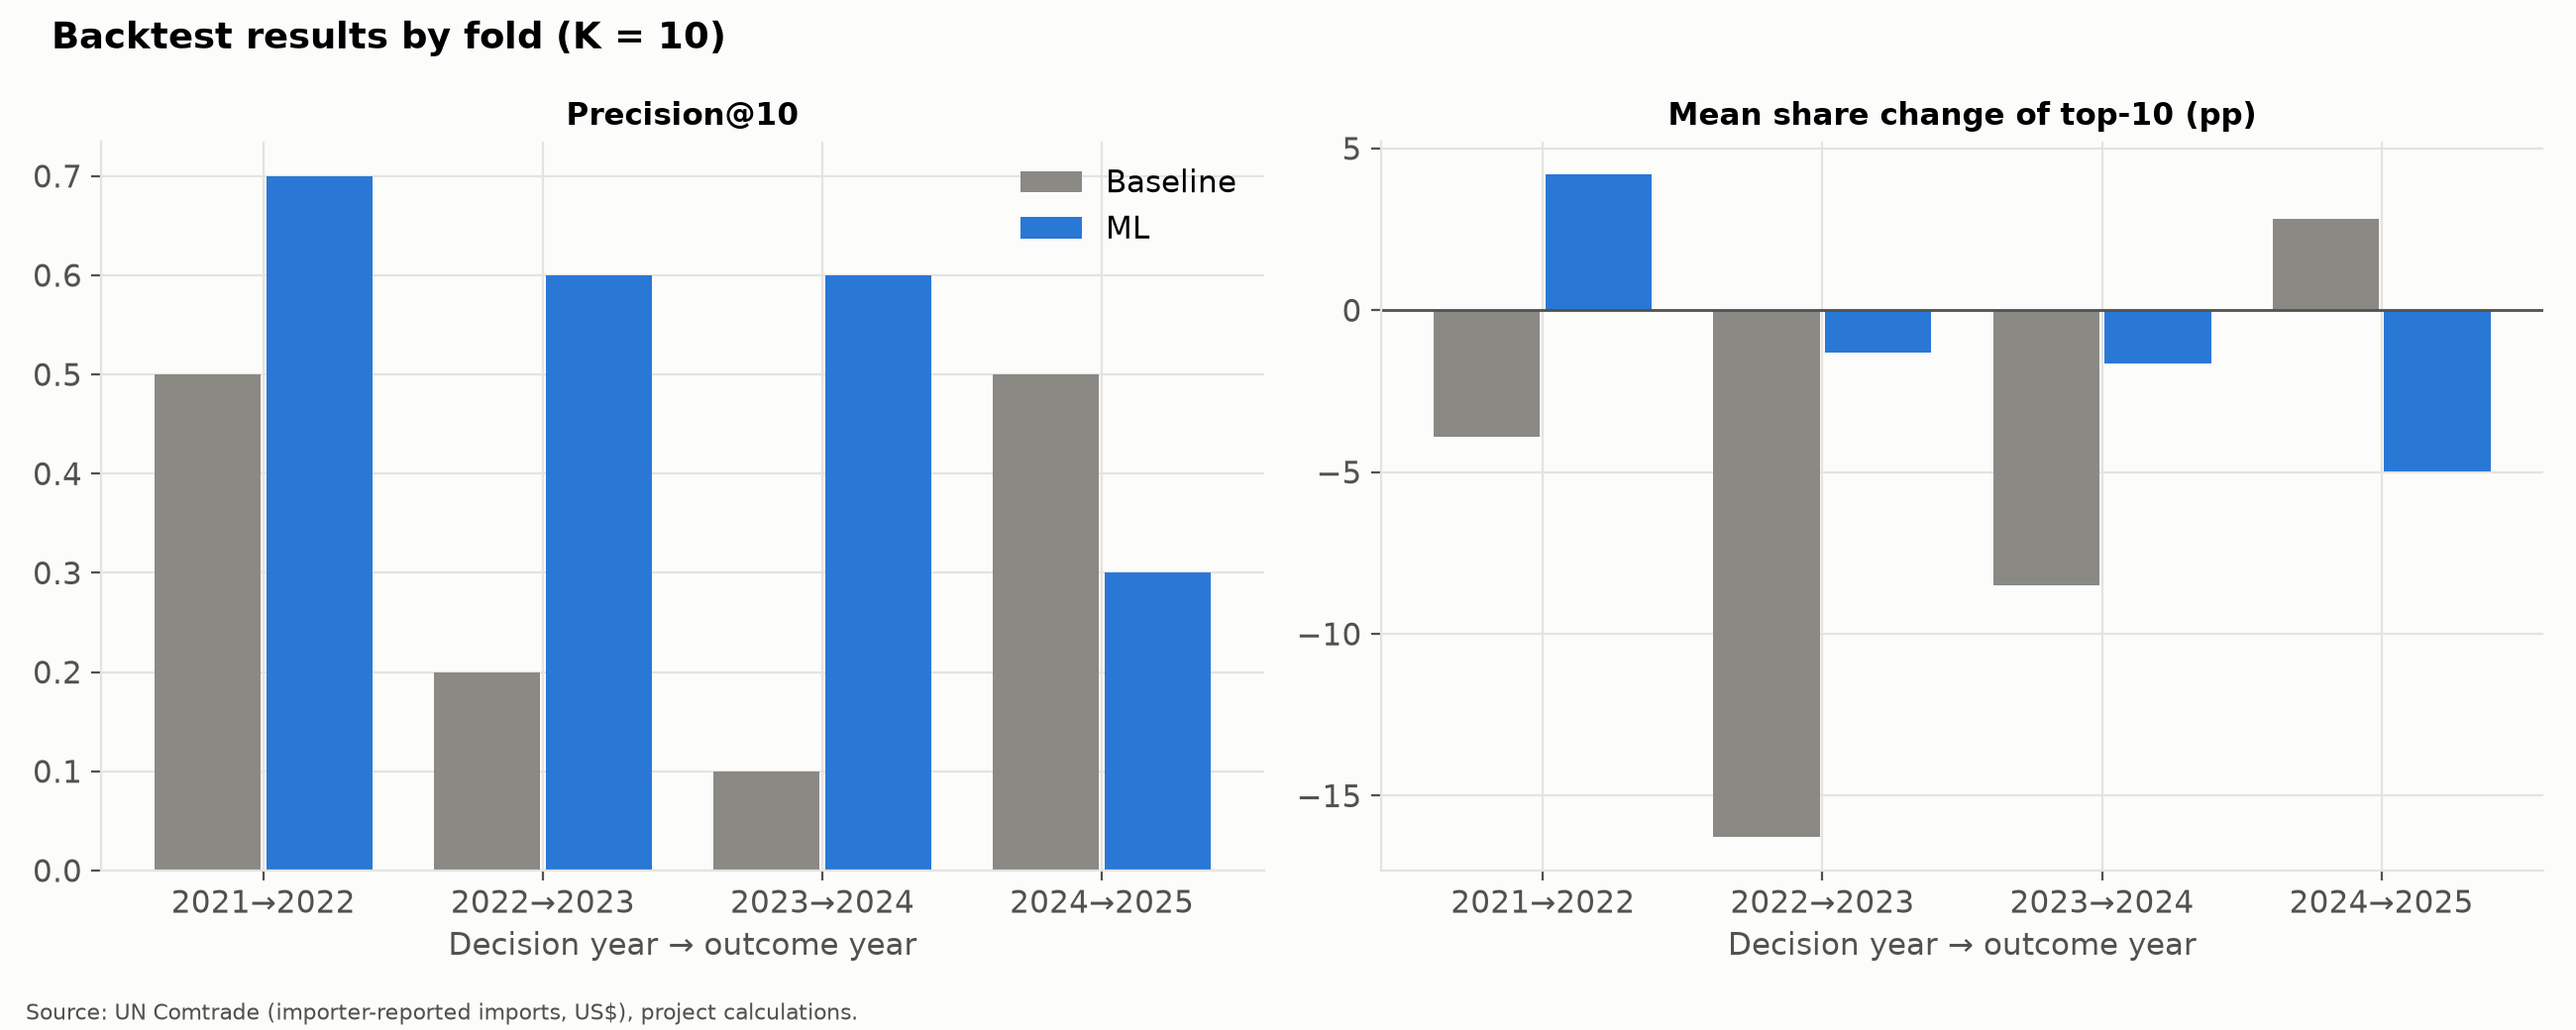

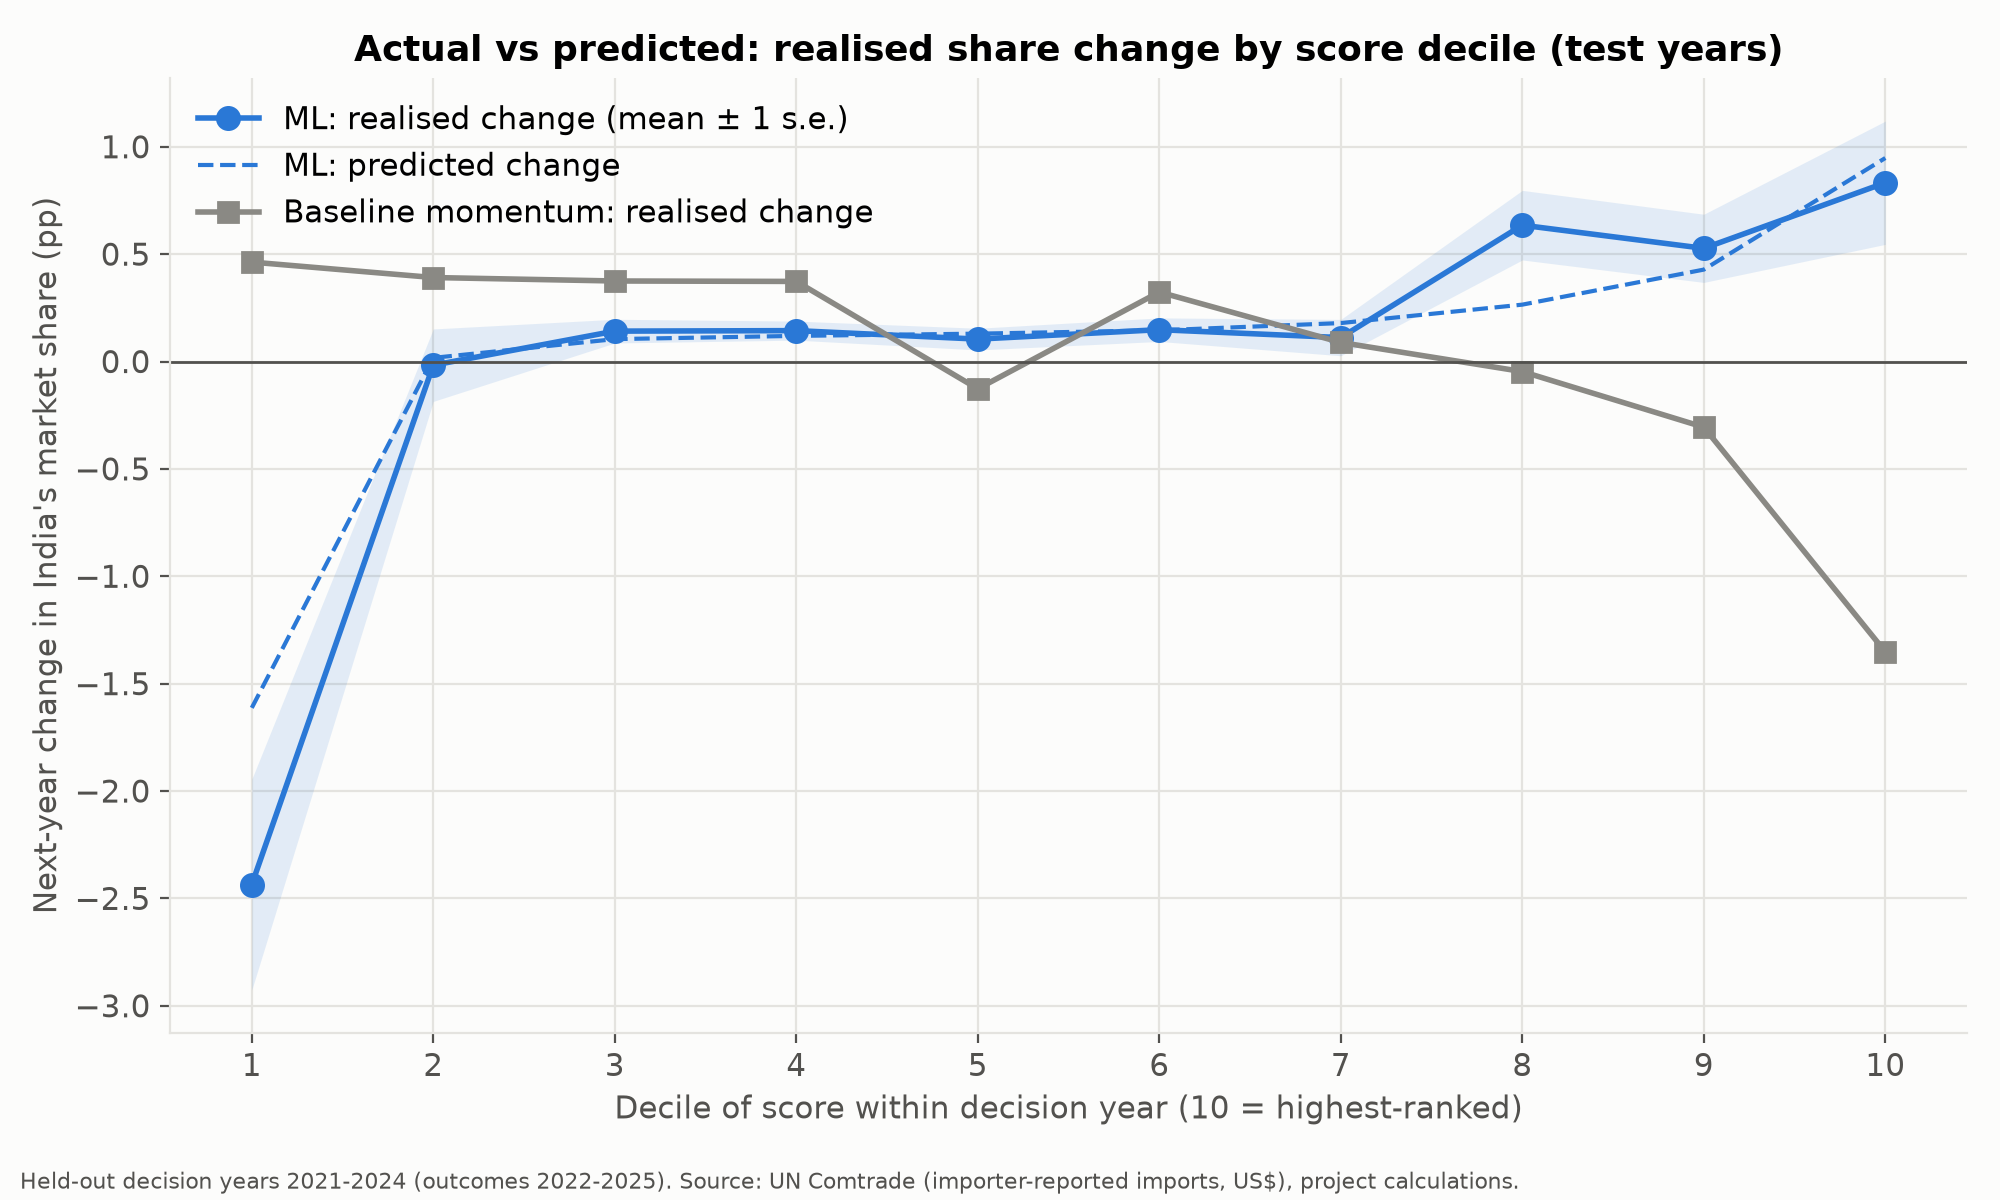

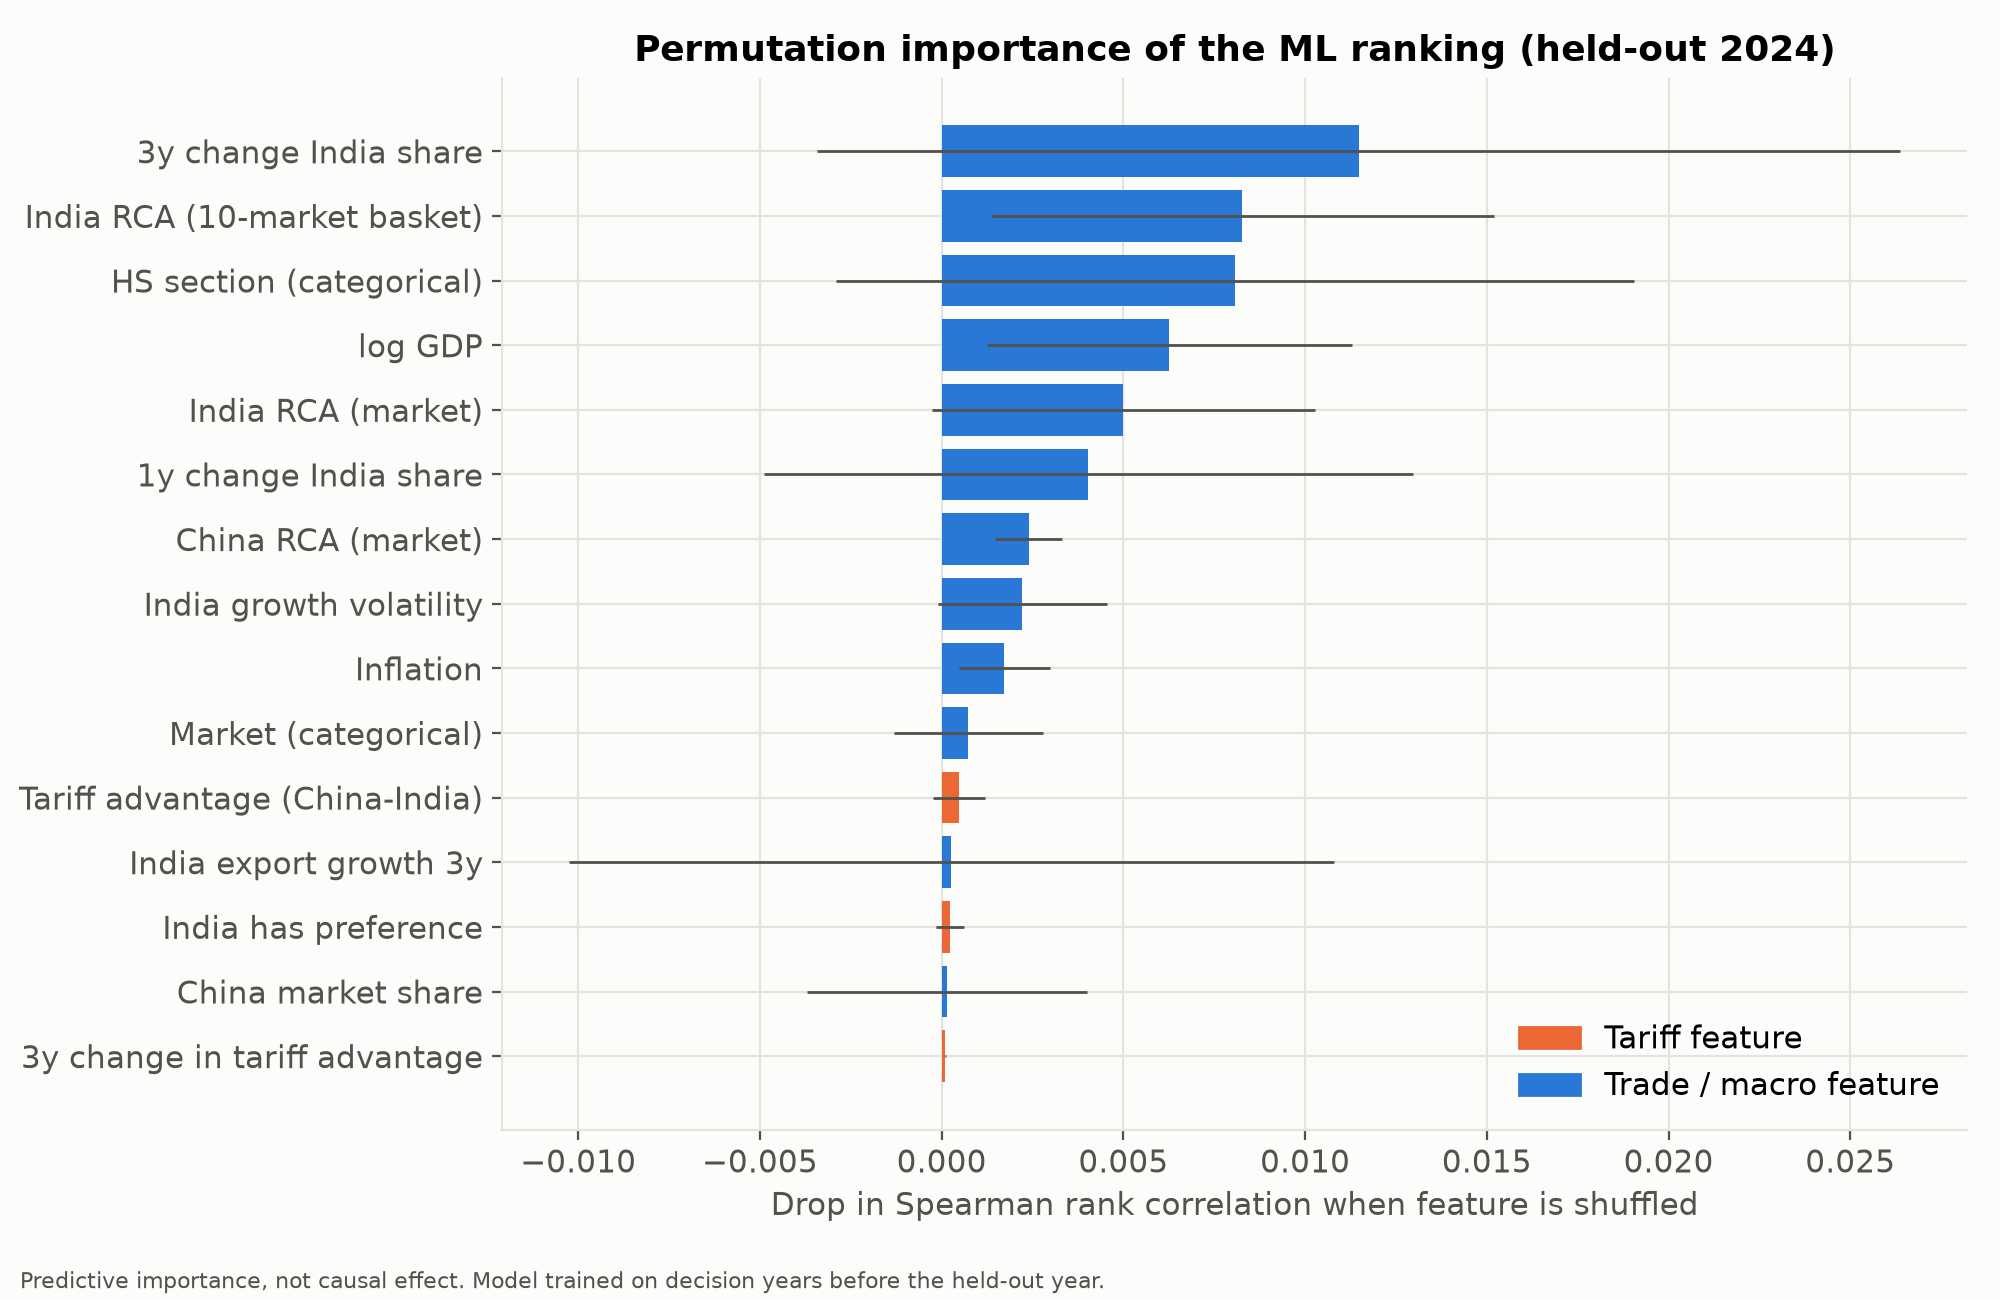

In [6]:
for f in ['11_performance_comparison','11b_backtest_by_year','09_actual_vs_predicted','08_feature_importance']:
    display(Image(f'outputs/figures/{f}.png', width=800))

In [7]:
pd.read_csv('outputs/metrics/diversion_regressions.csv').round(4)

,spec,variable,coef,se,p_value,n,r2
0,"(1) level, market-year FE",tariff_adv,0.0254,0.0192,0.1866,11413,0.0175
1,(2) + product FE + controls,tariff_adv,0.0286,0.0247,0.2478,11413,0.1006
2,(3) change in advantage,tariff_adv,0.0222,0.0200,0.2668,11413,0.1008
3,(3) change in advantage,d1_tariff_adv,0.0862,0.1213,0.4775,11413,0.1008
4,(4) export growth outcome,tariff_adv,0.0040,0.0025,0.1068,11413,0.2247
5,(4) export growth outcome,d1_tariff_adv,0.0030,0.0080,0.7117,11413,0.2247
